# Phân tích lợi suất và rủi ro cổ phiếu S&P 500 (2014–2017)

**Mục tiêu:** kiểm tra dữ liệu, so sánh lợi suất–rủi ro lịch sử, phân nhóm theo quy tắc và diễn giải kết quả. **Không triển khai học máy.**

Notebook chứa đầy đủ code phân tích, đồng bộ với `sp500_analysis.py`. Mở từ thư mục project, chọn Python `.venv`, rồi **Run All**. Giữ `analysis_config.py` và CSV cùng thư mục; tạo `outputs/tables`, `outputs/figures` nếu chưa có (chạy `powershell -NoProfile -ExecutionPolicy Bypass -File .\run.ps1 -Install` để chuẩn bị và chạy script). Thay đổi tham số trong `analysis_config.py` trước khi khởi động lại kernel và Run All. Dữ liệu gốc không bị ghi đè.

Đọc phương pháp trong [METHODOLOGY.md](METHODOLOGY.md) và hướng dẫn trong [README.md](README.md).

# 1. Nhập dữ liệu — chương 6–7

**Câu hỏi:** CSV chứa những biến và quan sát nào? Đọc file cục bộ; kiểm tra các cột và ví dụ đầu bảng. Một dòng là một mã trong một phiên. Giá không được mặc định là adjusted prices hay total return.

In [1]:
"""Phân tích mô tả S&P 500; chạy bằng .\run.ps1 từ PowerShell.

Chỉ dùng CSV cục bộ. Không huấn luyện ML theo lựa chọn của người dùng.
Các hàm phân tích được dùng chung với notebook, không sửa dữ liệu gốc.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analysis_config import DATA_FILE, OUTPUT_DIR, MIN_COVERAGE, EXTREME_RETURN


def save_table(frame, name):
    frame.to_csv(f"{OUTPUT_DIR}/tables/{name}.csv", index=False, encoding="utf-8-sig")


def load_data():
    raw = pd.read_csv(DATA_FILE)
    print("Số dòng dữ liệu gốc:", len(raw))
    print("Tên cột:", list(raw))
    return raw

raw = load_data()
print(raw[:5])

Số dòng dữ liệu gốc: 497472
Tên cột: ['symbol', 'date', 'open', 'high', 'low', 'close', 'volume']
  symbol        date      open      high       low     close    volume
0    AAL  2014-01-02   25.0700   25.8200   25.0600   25.3600   8998943
1   AAPL  2014-01-02   79.3828   79.5756   78.8601   79.0185  58791957
2    AAP  2014-01-02  110.3600  111.8800  109.2900  109.7400    542711
3   ABBV  2014-01-02   52.1200   52.3300   51.5200   51.9800   4569061
4    ABC  2014-01-02   70.1100   70.2300   69.4800   69.8900   1148391


# 2. Kiểm toán và làm sạch — chương 8–9

**Câu hỏi:** Những dòng nào cần cách ly, những dòng nào vẫn dùng được? Kiểm tra thiếu, trùng, không hữu hạn, dấu giá/volume và quan hệ OHLC. Không điền giá bằng 0. Giữ close hợp lệ khi chỉ thiếu OHL/volume, nhưng đánh dấu complete_ohlcv=False. Bảng quality_summary đếm lỗi có chồng lấn; cleaning_steps đếm loại tuần tự không trùng.

In [2]:
def clean_data(raw):
    """Giữ close dùng được; lỗi volume/OHL chỉ cấm phép tính cần các trường đó.

    Khi OHLC mâu thuẫn, không biết giá nào sai nên cách ly cả dòng.
    Trùng hoàn toàn giữ bản đầu; trùng khóa khác nội dung cách ly cả nhóm.
    Số dòng lỗi trong quality_flags có thể chồng lấn. cleaning_steps là tuần tự.
    """
    columns = ["symbol", "date", "open", "high", "low", "close", "volume"]
    data = raw[columns].copy()
    data["symbol"] = data["symbol"].str.strip().str.upper()
    data["date"] = pd.to_datetime(data["date"], errors="coerce")
    exact_duplicate = np.array(data.duplicated(subset=columns))
    data["source_row"] = np.arange(len(data)) + 2  # Dòng CSV, tính cả header.

    missing_rows = []
    schema_rows = []
    for column in columns:
        missing_rows.append({"column": column, "missing": int(raw[column].isna().sum())})
        schema_rows.append({"column": column, "loaded_dtype": str(np.array(raw[column]).dtype)})
    save_table(pd.DataFrame(missing_rows), "missing_by_column")
    save_table(pd.DataFrame(schema_rows), "schema")

    flags = pd.DataFrame({"source_row": data["source_row"], "symbol": data["symbol"],
                          "date": data["date"]})
    flags["missing_symbol"] = data["symbol"].isna() | (data["symbol"] == "")
    flags["invalid_date"] = data["date"].isna()
    flags["exact_duplicate"] = exact_duplicate
    flags["duplicate_key_raw"] = data.duplicated(subset=["symbol", "date"], keep=False)
    for column in ["open", "high", "low", "close", "volume"]:
        values = np.array(data[column], dtype=float)
        flags[f"missing_{column}"] = data[column].isna()
        flags[f"nonfinite_{column}"] = ~np.isfinite(values)
        flags[f"invalid_sign_{column}"] = values < 0 if column == "volume" else values <= 0

    inconsistent = ((data["high"] < data["low"]) | (data["high"] < data["open"])
                    | (data["high"] < data["close"]) | (data["low"] > data["open"])
                    | (data["low"] > data["close"]))
    flags["inconsistent_ohlc"] = inconsistent
    summary = []
    for name in list(flags)[3:]:
        summary.append({"check": name, "flagged_rows": int(flags[name].sum())})
    audit = pd.DataFrame(summary)
    save_table(audit, "quality_summary")
    save_table(flags, "quality_flags")

    # Lịch tham chiếu lấy từ toàn bộ ngày hợp lệ, trước khi cách ly giá.
    valid_dates = data[data["date"].notna()]["date"]
    calendar = np.unique(np.array(valid_dates, dtype="datetime64[D]"))
    day_numbers = calendar.astype(np.int32)
    session_lookup = {int(day): i for i, day in enumerate(day_numbers)}

    data["exclude_reason"] = np.where(exact_duplicate, "exact_duplicate", "")
    remaining = data[~exact_duplicate].copy()
    conflicting = remaining.duplicated(subset=["symbol", "date"], keep=False)
    conflict_ids = np.array(remaining[conflicting]["source_row"])
    conflict = np.isin(np.array(data["source_row"]), conflict_ids)
    missing_key = np.array(flags["missing_symbol"] | flags["invalid_date"])
    bad_close = ~np.isfinite(np.array(data["close"], dtype=float)) | (np.array(data["close"]) <= 0)
    steps = [{"step": "raw", "removed": 0, "remaining": len(data)}]
    keep = np.ones(len(data), dtype=bool)
    for name, mask in [("exact_duplicate", exact_duplicate), ("missing_key", missing_key),
                       ("conflicting_key", conflict), ("invalid_close", bad_close),
                       ("inconsistent_ohlc", np.array(inconsistent))]:
        newly_removed = keep & mask
        data["exclude_reason"] = np.where(newly_removed, name, data["exclude_reason"])
        keep = keep & ~mask
        steps.append({"step": name, "removed": int(newly_removed.sum()),
                      "remaining": int(keep.sum())})
    excluded = data[~keep].copy()
    clean = data[keep].copy()
    clean = clean.set_index(["symbol", "date"]).sort_index().reset_index()
    clean_days = np.array(clean["date"], dtype="datetime64[D]").astype(np.int32)
    clean["session_id"] = [session_lookup[int(day)] for day in clean_days]
    # Không dùng volume hoặc OHL lỗi để diễn giải thanh khoản/biên độ.
    complete_ohlcv = np.ones(len(clean), dtype=bool)
    for column in ["open", "high", "low", "close", "volume"]:
        values = np.array(clean[column], dtype=float)
        valid_sign = values >= 0 if column == "volume" else values > 0
        complete_ohlcv = complete_ohlcv & np.isfinite(values) & valid_sign
    clean["complete_ohlcv"] = complete_ohlcv
    save_table(excluded, "excluded_rows")
    save_table(pd.DataFrame(steps), "cleaning_steps")
    save_table(clean, "clean_prices")
    save_table(pd.DataFrame({"date": calendar, "session_id": np.arange(len(calendar))}), "calendar")
    print("Số dòng dùng cho phân tích close:", len(clean))
    print("Dòng cách ly/loại trùng:", len(excluded))
    print(pd.DataFrame(steps))
    return clean, audit, calendar, pd.DataFrame(steps)

clean, audit, calendar, steps = clean_data(raw)
print(audit[audit["flagged_rows"] > 0])

Số dòng dùng cho phân tích close: 497460
Dòng cách ly/loại trùng: 12
                step  removed  remaining
0                raw        0     497472
1    exact_duplicate        0     497472
2        missing_key        0     497472
3    conflicting_key        0     497472
4      invalid_close        0     497472
5  inconsistent_ohlc       12     497460
                check  flagged_rows
4        missing_open            11
5      nonfinite_open            11
7        missing_high             8
8      nonfinite_high             8
10        missing_low             8
11      nonfinite_low             8
19  inconsistent_ohlc            12


# 3. Chỉ tiêu lợi suất–rủi ro — chương 4–5, 10–11

**Câu hỏi:** So sánh các mã trên cùng cơ sở như thế nào?

- Daily return: $r_t=P_t/P_{t-1}-1$, chỉ trong cùng mã và hai phiên liền kề theo lịch dataset.
- Cumulative price return: $P_t/P_0-1$; chỉ số chuẩn hóa: $100P_t/P_0$.
- Trung bình daily return và độ lệch chuẩn tổng thể (`std`, ddof=0).
- CAGR: $(P_{end}/P_{start})^{1/Y}-1$, $Y$ là số ngày lịch/365.25.

Mã xếp hạng phải có cả hai đầu kỳ chung, >=95% phiên giá hợp lệ và >=95% cặp phiên có daily return (tham số MIN_COVERAGE). Lợi suất qua khoảng thiếu phiên chỉ lưu observed_return. Bảng all có chỉ tiêu kỳ riêng cho mã không đạt; không dùng chúng trong xếp hạng chung.

In [3]:
def price_metrics(close, sessions, days):
    """Không dùng shift/pct_change; chỉ chia mảng trong cùng mã.

    Return qua khoảng trống vẫn lưu ở observed_return nhưng không dùng để
    tính trung bình/volatility một phiên. Lịch là lịch quan sát từ dataset.
    """
    n = len(close)
    observed = np.full(n, float("nan"))
    daily = np.full(n, float("nan"))
    gaps = np.zeros(n, dtype=bool)
    if n > 1:
        observed[1:] = close[1:] / close[:-1] - 1
        consecutive = sessions[1:] - sessions[:-1] == 1
        daily[1:] = np.where(consecutive, observed[1:], float("nan"))
        gaps[1:] = ~consecutive
    valid_daily = daily[np.isfinite(daily)]
    average = valid_daily.mean() if len(valid_daily) > 0 else float("nan")
    volatility = valid_daily.std() if len(valid_daily) >= 2 else float("nan")
    years = (int(days[-1]) - int(days[0])) / 365.25
    cagr = (close[-1] / close[0]) ** (1 / years) - 1 if years > 0 else float("nan")
    cumulative = close / close[0] - 1
    return observed, daily, gaps, cumulative, average, volatility, cagr


def analyze_prices(clean, calendar):
    metrics = []
    daily_parts = []
    common_days = calendar.astype(np.int32)
    for symbol, part in clean.groupby("symbol"):
        part = part.copy()
        close = np.array(part["close"], dtype=float)
        sessions = np.array(part["session_id"])
        dates = np.array(part["date"], dtype="datetime64[D]")
        days = dates.astype(np.int32)
        observed, daily, gaps, cumulative, average, volatility, cagr = price_metrics(close, sessions, days)
        n_returns = int(np.isfinite(daily).sum())
        coverage = len(part) / len(calendar)
        return_coverage = n_returns / (len(calendar) - 1) if len(calendar) > 1 else 0.0
        full_endpoints = days[0] == common_days[0] and days[-1] == common_days[-1]
        eligible = (full_endpoints and coverage >= MIN_COVERAGE
                    and return_coverage >= MIN_COVERAGE and np.isfinite(cagr)
                    and np.isfinite(volatility))
        reasons = []
        if not full_endpoints:
            reasons.append("missing_common_endpoint")
        if coverage < MIN_COVERAGE:
            reasons.append("low_price_coverage")
        if return_coverage < MIN_COVERAGE:
            reasons.append("low_return_coverage")
        if not np.isfinite(cagr) or not np.isfinite(volatility):
            reasons.append("insufficient_metrics")
        metrics.append({"symbol": symbol, "start_date": str(dates[0]), "end_date": str(dates[-1]),
                        "observations": len(part), "daily_returns": n_returns,
                        "price_coverage": coverage, "return_coverage": return_coverage,
                        "gap_returns": int(gaps.sum()), "cumulative_price_return": float(cumulative[-1]),
                        "average_daily_return": average, "daily_volatility": volatility, "cagr": cagr,
                        "extreme_daily_returns": int((np.abs(daily) >= EXTREME_RETURN).sum()),
                        "eligible": bool(eligible), "exclusion_reason": ";".join(reasons)})
        part["observed_return"] = observed
        part["daily_return"] = daily
        part["gap_before"] = gaps
        part["cumulative_price_return"] = cumulative
        part["normalized_price"] = 100 * (1 + cumulative)
        part["extreme_return_flag"] = np.abs(observed) >= EXTREME_RETURN
        daily_parts.append(part)
    metrics = pd.DataFrame(metrics)
    daily = pd.concat(daily_parts, axis=0).reset_index(drop=True)
    save_table(metrics, "stock_metrics_all")
    save_table(daily, "daily_returns")
    save_table(daily[daily["extreme_return_flag"]], "extreme_returns_review")
    print("Số mã được tính chỉ tiêu:", len(metrics))
    print("Số mã đủ điều kiện so sánh:", int(metrics["eligible"].sum()))
    return metrics, daily

metrics, daily = analyze_prices(clean, calendar)
print(metrics[:5])

Số mã được tính chỉ tiêu: 505
Số mã đủ điều kiện so sánh: 483
  symbol  start_date    end_date  observations  daily_returns  price_coverage  \
0      A  2014-01-02  2017-12-29          1007           1006             1.0   
1    AAL  2014-01-02  2017-12-29          1007           1006             1.0   
2    AAP  2014-01-02  2017-12-29          1007           1006             1.0   
3   AAPL  2014-01-02  2017-12-29          1007           1006             1.0   
4   ABBV  2014-01-02  2017-12-29          1007           1006             1.0   

   return_coverage  gap_returns  cumulative_price_return  \
0              1.0            0                 0.191425   
1              1.0            0                 1.051656   
2              1.0            0                -0.091580   
3              1.0            0                 1.141650   
4              1.0            0                 0.860523   

   average_daily_return  daily_volatility      cagr  extreme_daily_returns  \
0           

# 4. Phân nhóm theo quy tắc — chương 10–11

**Câu hỏi:** Có những kết hợp hiệu suất và biến động nào?

Ngưỡng là trung bình CAGR và daily volatility của tập đủ điều kiện. Bằng ngưỡng thuộc phía cao, dung sai số thực tuyệt đối 1e-12. A: cao/thấp; B: cao/cao; C: thấp/thấp; D: thấp/cao (CAGR/volatility). Đây không phải phân cụm học máy. Chọn hai đầu CAGR mỗi nhóm để có tối đa 8 ví dụ; quy tắc phá hòa nằm trong code và báo cáo.

In [4]:
GROUP_NAMES = {"A": "CAGR cao / biến động thấp", "B": "CAGR cao / biến động cao",
               "C": "CAGR thấp / biến động thấp", "D": "CAGR thấp / biến động cao"}


def group_stocks(metrics):
    eligible = metrics[metrics["eligible"]].copy()
    cagr_threshold = np.array(eligible["cagr"]).mean()
    volatility_threshold = np.array(eligible["daily_volatility"]).mean()
    # Sai số tuyệt đối 1e-12 ở đơn vị tỷ lệ: coi bằng ngưỡng về mặt số học.
    high_return = (eligible["cagr"] >= cagr_threshold) | (np.abs(eligible["cagr"] - cagr_threshold) <= 1e-12)
    high_risk = ((eligible["daily_volatility"] >= volatility_threshold)
                 | (np.abs(eligible["daily_volatility"] - volatility_threshold) <= 1e-12))
    eligible["group"] = np.where(high_return, np.where(high_risk, "B", "A"),
                                  np.where(high_risk, "D", "C"))
    summaries = []
    selected_parts = []
    for group in ["A", "B", "C", "D"]:
        members = eligible[eligible["group"] == group].copy()
        summaries.append({"group": group, "definition": GROUP_NAMES[group], "stocks": len(members),
                          "mean_cagr": np.array(members["cagr"]).mean() if len(members) else float("nan"),
                          "mean_daily_volatility": np.array(members["daily_volatility"]).mean()
                          if len(members) else float("nan")})
        if len(members) > 0:
            ranked = members.set_index(["cagr", "symbol"]).sort_index().reset_index()
            first = ranked[:1].copy()
            first["selection_reason"] = f"CAGR thấp nhất trong nhóm {group} (hòa: symbol tăng dần)"
            selected_parts.append(first)
            if len(members) > 1:
                # Chọn symbol nhỏ nhất nếu nhiều mã cùng CAGR cao nhất.
                highest_cagr = np.array(ranked["cagr"])[-1]
                last = ranked[ranked["cagr"] == highest_cagr][:1].copy()
                if np.array(last["symbol"])[0] == np.array(first["symbol"])[0]:
                    last = ranked[-1:].copy()
                last["selection_reason"] = f"CAGR cao nhất trong nhóm {group} (hòa: symbol tăng dần)"
                selected_parts.append(last)
    selected = pd.concat(selected_parts, axis=0).reset_index(drop=True)
    summary = pd.DataFrame(summaries)
    thresholds = pd.DataFrame({"metric": ["cagr", "daily_volatility"],
                               "threshold": [cagr_threshold, volatility_threshold],
                               "rule": ["high_if_greater_or_equal_tol_1e-12", "high_if_greater_or_equal_tol_1e-12"]})
    save_table(eligible, "stock_groups")
    save_table(summary, "group_summary")
    save_table(selected, "selected_stocks")
    save_table(thresholds, "group_thresholds")
    print(summary)
    return eligible, summary, selected, thresholds

eligible, summary, selected, thresholds = group_stocks(metrics)
print(thresholds)
print(selected[["symbol", "group", "cagr", "daily_volatility", "selection_reason"]])

  group                  definition  stocks  mean_cagr  mean_daily_volatility
0     A   CAGR cao / biến động thấp     180   0.162746               0.012406
1     B    CAGR cao / biến động cao      77   0.219779               0.019129
2     C  CAGR thấp / biến động thấp     119   0.029436               0.012711
3     D   CAGR thấp / biến động cao     107  -0.040492               0.020756
             metric  threshold                                rule
0              cagr   0.093970  high_if_greater_or_equal_tol_1e-12
1  daily_volatility   0.015403  high_if_greater_or_equal_tol_1e-12
  symbol group      cagr  daily_volatility  \
0     CB     A  0.095122          0.009367   
1    STZ     A  0.349030          0.013104   
2   CTSH     B  0.095160          0.016000   
3   NVDA     B  0.872148          0.023727   
4     GE     C -0.107763          0.011842   
5      C     C  0.092572          0.015192   
6    CHK     D -0.379768          0.045526   
7   CTXS     D  0.089607          0.01790

# 5. Trực quan hóa — chương 12–13

**Câu hỏi:** Các bảng chỉ tiêu cho thấy điều gì khi đặt cạnh nhau?

Năm hình lần lượt trình bày phân phối, xếp hạng, quan hệ hiệu suất–rủi ro, số mã theo nhóm và giá chuẩn hóa. Histogram trái giữ cả đuôi phân phối; bên phải phóng to ±10%. Các đường giá cùng mốc 100, thiếu phiên để đứt đường. Các ô giá có thang dọc riêng. Giá trị cột được vẽ từ đường 0, kể cả khi CAGR âm.

Đã xuất 5 hình PNG vào outputs/figures.


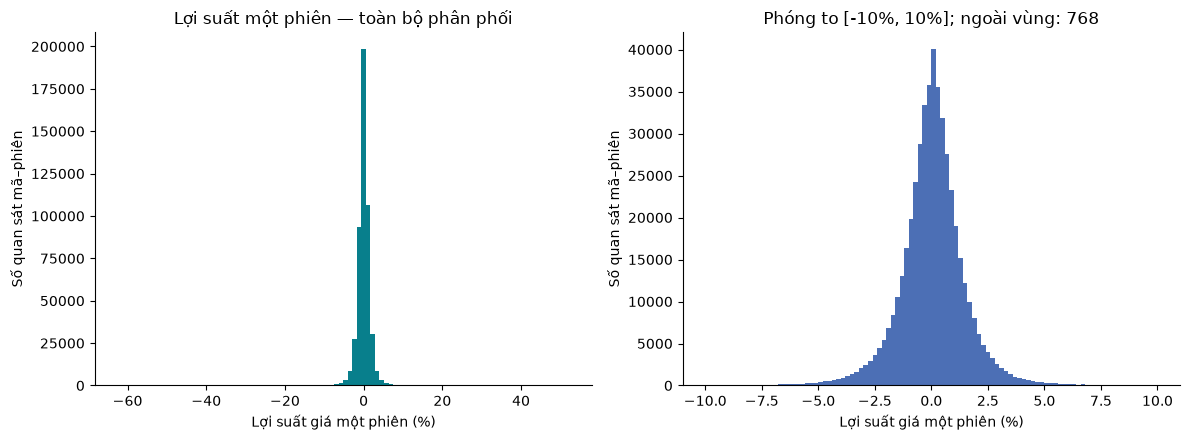

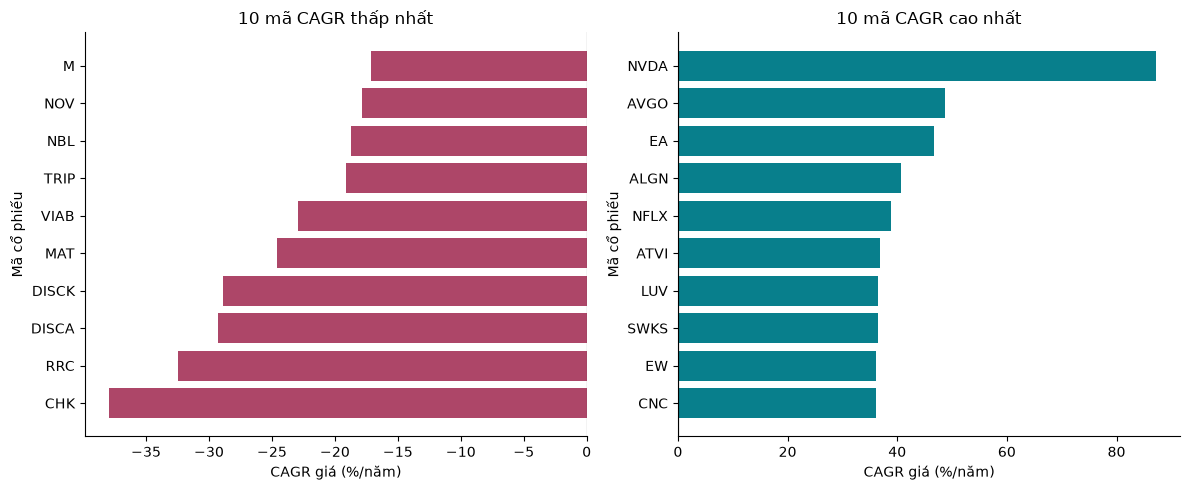

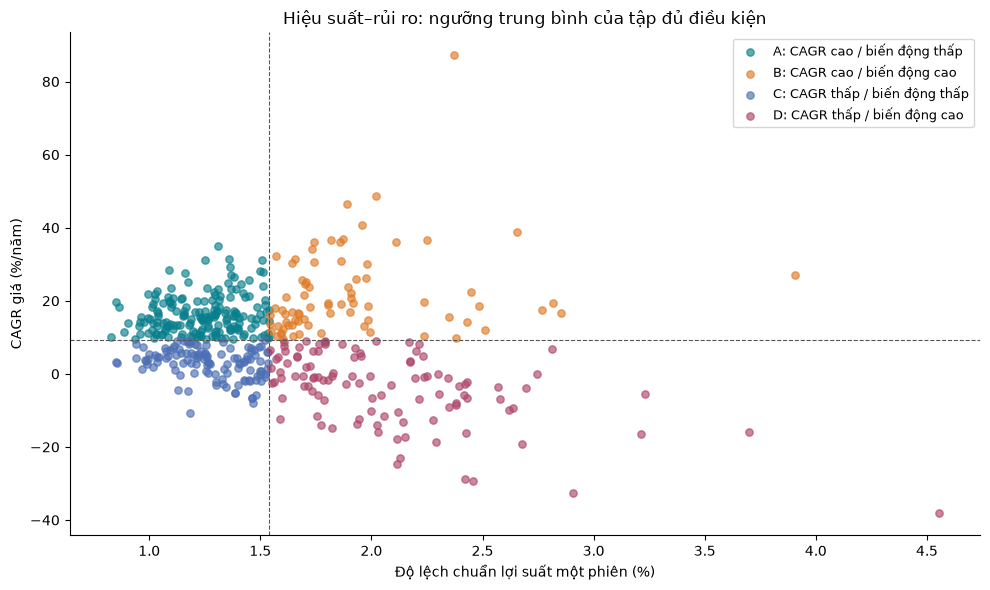

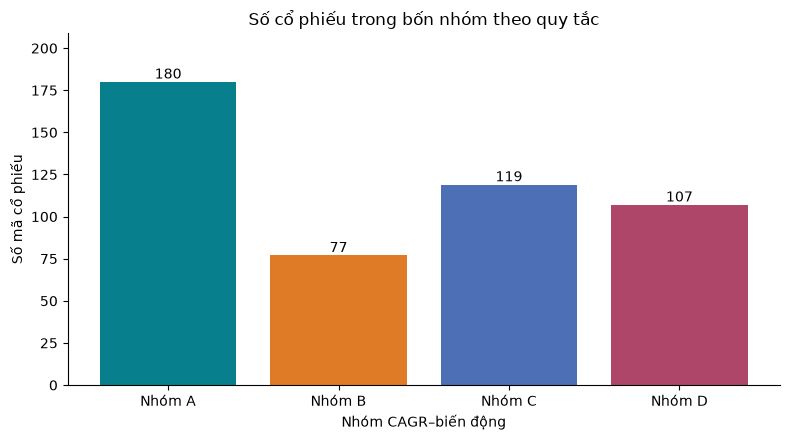

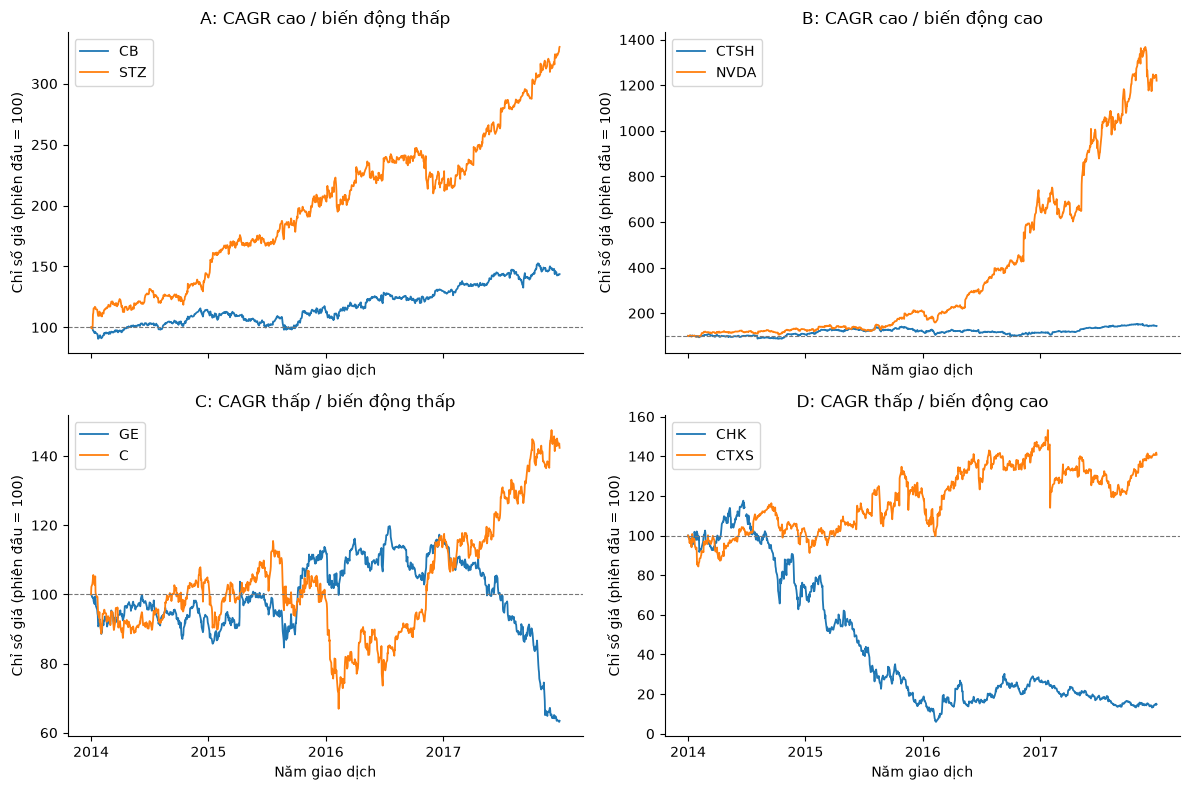

In [5]:
def save_figure(name):
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/figures/{name}.png", dpi=160)


def make_figures(eligible, daily, summary, selected, thresholds):
    plt.rcParams["font.family"] = "DejaVu Sans"
    plt.rcParams["axes.spines.top"] = False
    plt.rcParams["axes.spines.right"] = False
    palette = {"A": "#087f8c", "B": "#df7b27", "C": "#4c6fb5", "D": "#ad4668"}
    chosen_daily = daily[np.isin(np.array(daily["symbol"]), np.array(eligible["symbol"]))]
    returns = np.array(chosen_daily["daily_return"])
    returns = returns[np.isfinite(returns)] * 100
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].hist(returns, bins=100, color="#087f8c")
    axes[0].set_title("Lợi suất một phiên — toàn bộ phân phối")
    center = returns[np.abs(returns) <= 10]
    axes[1].hist(center, bins=100, color="#4c6fb5")
    axes[1].set_title(f"Phóng to [-10%, 10%]; ngoài vùng: {len(returns)-len(center):,}")
    for ax in axes:
        ax.set_xlabel("Lợi suất giá một phiên (%)")
        ax.set_ylabel("Số quan sát mã–phiên")
        ax.set_ylim(bottom=0)
    save_figure("01_return_distribution")

    ranked = eligible.set_index(["cagr", "symbol"]).sort_index().reset_index()
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, subset, title, color in [(axes[0], ranked[:10], "10 mã CAGR thấp nhất", "#ad4668"),
                                      (axes[1], ranked[-10:], "10 mã CAGR cao nhất", "#087f8c")]:
        ax.barh(list(subset["symbol"]), np.array(subset["cagr"]) * 100, color=color)
        ax.axvline(0, color="#333333", linewidth=0.8)
        ax.set_title(title)
        ax.set_xlabel("CAGR giá (%/năm)")
        ax.set_ylabel("Mã cổ phiếu")
    save_figure("02_cagr_ranking")

    fig, ax = plt.subplots(figsize=(10, 6))
    for group in ["A", "B", "C", "D"]:
        members = eligible[eligible["group"] == group]
        ax.scatter(np.array(members["daily_volatility"]) * 100,
                   np.array(members["cagr"]) * 100, alpha=0.65, s=28,
                   color=palette[group], label=f"{group}: {GROUP_NAMES[group]}")
    bounds = np.array(thresholds["threshold"])
    ax.axhline(bounds[0] * 100, color="#555555", linestyle="--", linewidth=0.8)
    ax.axvline(bounds[1] * 100, color="#555555", linestyle="--", linewidth=0.8)
    ax.set_title("Hiệu suất–rủi ro: ngưỡng trung bình của tập đủ điều kiện")
    ax.set_xlabel("Độ lệch chuẩn lợi suất một phiên (%)")
    ax.set_ylabel("CAGR giá (%/năm)")
    ax.legend(fontsize=9)
    save_figure("03_risk_return_groups")

    fig, ax = plt.subplots(figsize=(8, 4.5))
    counts = np.array(summary["stocks"])
    ax.bar([f"Nhóm {g}" for g in summary["group"]], counts,
           color=[palette[g] for g in summary["group"]])
    for i, count in enumerate(counts):
        ax.text(i, count, str(count), ha="center", va="bottom")
    ax.set_title("Số cổ phiếu trong bốn nhóm theo quy tắc")
    ax.set_xlabel("Nhóm CAGR–biến động")
    ax.set_ylabel("Số mã cổ phiếu")
    ax.set_ylim(0, counts.max() * 1.16)
    save_figure("04_group_counts")

    # Cùng mốc 100; chèn NaN ở phiên thiếu để không nối đường qua khoảng trống.
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
    # Dùng session_id trực tiếp, không suy ra lịch riêng của từng mã.
    calendar_frame = pd.read_csv(f"{OUTPUT_DIR}/tables/calendar.csv")
    all_dates = pd.to_datetime(calendar_frame["date"])
    year_labels = np.unique(np.array([str(date)[:4] for date in calendar_frame["date"]]))
    year_ticks = pd.to_datetime([f"{year}-01-02" for year in year_labels])
    for i, group in enumerate(["A", "B", "C", "D"]):
        ax = axes[i // 2, i % 2]
        members = selected[selected["group"] == group]
        for symbol in members["symbol"]:
            series = daily[daily["symbol"] == symbol]
            normalized = np.full(len(all_dates), float("nan"))
            normalized[np.array(series["session_id"], dtype=int)] = np.array(series["normalized_price"])
            ax.plot(all_dates, normalized, label=symbol, linewidth=1.3)
        ax.axhline(100, color="#777777", linestyle="--", linewidth=0.8)
        ax.set_title(f"{group}: {GROUP_NAMES[group]}")
        ax.set_xlabel("Năm giao dịch")
        ax.set_ylabel("Chỉ số giá (phiên đầu = 100)")
        ax.set_xticks(year_ticks)
        ax.set_xticklabels(year_labels)
        if len(members):
            ax.legend()
    save_figure("05_selected_normalized_prices")
    print("Đã xuất 5 hình PNG vào outputs/figures.")

make_figures(eligible, daily, summary, selected, thresholds)

# 6. Diễn giải kết quả và storytelling

Phần dưới được sinh từ các bảng **của lần chạy hiện tại**, không điền sẵn kết quả. Bản Markdown có hình nằm tại [outputs/report.md](outputs/report.md). ML đã được loại khỏi phạm vi theo yêu cầu người dùng. Các hàm thư viện trong mã phân tích đã được đối chiếu allowed_knowledge_reference.md; hạ tầng Jupyter và bộ kiểm thử phát triển không phải thuật toán của bài.

In [6]:
def markdown_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    for row in rows:
        lines.append("| " + " | ".join([str(value) for value in row]) + " |")
    return "\n" + "\n".join(lines) + "\n"


def write_report(raw, clean, audit, calendar, steps, metrics, daily, eligible, summary, selected, thresholds):
    ranked = eligible.set_index(["cagr", "symbol"]).sort_index().reset_index()
    top_symbol = list(ranked["symbol"])[-1]
    bottom_symbol = list(ranked["symbol"])[0]
    top_cagr = np.array(ranked["cagr"])[-1]
    bottom_cagr = np.array(ranked["cagr"])[0]
    bounds = np.array(thresholds["threshold"])
    extreme_count = int(daily["extreme_return_flag"].sum())
    gap_count = int(daily["gap_before"].sum())
    invalid_ohlcv = int((~np.array(clean["complete_ohlcv"])).sum())
    group_rows = []
    for group, count, cagr, vol in zip(summary["group"], summary["stocks"], summary["mean_cagr"],
                                      summary["mean_daily_volatility"]):
        group_rows.append([group, GROUP_NAMES[group], count, f"{cagr:.2%}", f"{vol:.2%}"])
    selection_rows = []
    for symbol, group, cagr, vol, coverage, start, end, reason in zip(
            selected["symbol"], selected["group"], selected["cagr"], selected["daily_volatility"],
            selected["price_coverage"], selected["start_date"], selected["end_date"], selected["selection_reason"]):
        selection_rows.append([symbol, group, f"{cagr:.2%}", f"{vol:.2%}", f"{coverage:.2%}", start, end, reason])
    audit_rows = [[name, count] for name, count in zip(audit["check"], audit["flagged_rows"]) if count > 0]
    cleaning_rows = [[name, removed, remaining] for name, removed, remaining in
                     zip(steps["step"], steps["removed"], steps["remaining"])]
    report = [
        "# Phân tích lợi suất và rủi ro cổ phiếu S&P 500 (2014–2017)",
        "\nBáo cáo được sinh từ lần chạy script trên CSV cục bộ. Phạm vi: phân tích và phân nhóm; không có học máy.",
        "\n## 1. Nhập dữ liệu và kiểm toán chất lượng (chương 6–9)",
        "\n**Câu hỏi:** Dữ liệu có đủ chất lượng để so sánh biến động giá lịch sử không?",
        f"\nTệp gốc có **{len(raw):,} dòng**, **{len(metrics)} mã**; lịch quan sát có **{len(calendar):,} ngày**, "
        f"từ **{calendar[0]}** đến **{calendar[-1]}**. Schema: symbol, date, open, high, low, close, volume.",
        "\nCác kiểm tra có phát hiện (số dòng có thể chồng lấn):\n",
        markdown_table(["Kiểm tra", "Số dòng"], audit_rows),
        "\nSổ xử lý tuần tự, mỗi dòng bị loại chỉ được đếm một lần:\n",
        markdown_table(["Bước", "Loại trong bước", "Còn lại"], cleaning_rows),
        f"\nGiữ **{len(clean):,} dòng** cho phân tích close. Có **{invalid_ohlcv:,} dòng** trong số này "
        "không đủ OHLCV; không dùng chúng cho phép tính cần OHL/volume. Không điền giá thiếu bằng 0. "
        "Trùng hoàn toàn giữ dòng đầu; khóa trùng khác dữ liệu bị cách ly. OHLC mâu thuẫn bị cách ly vì không xác định được giá nào sai. "
        "Dòng bị loại và lý do được giữ trong `tables/excluded_rows.csv`.",
        f"\nCó **{gap_count:,} lợi suất qua khoảng thiếu phiên**: lưu riêng ở observed_return, không coi là daily_return. "
        f"Có **{extreme_count:,} biến động quan sát |return| ≥ {EXTREME_RETURN:.0%}** được gắn cờ, **không tự xóa**; "
        "xem `tables/extreme_returns_review.csv`. Cờ này không chứng minh một sự kiện chia tách cổ phiếu.",
        "\n## 2. Biến đổi và công thức (chương 4–5, 10–11)",
        "\n**Câu hỏi:** Đo hiệu suất và rủi ro trên cùng cơ sở như thế nào?",
        "\n- Lợi suất một phiên: `close_t / close_(t-1) - 1`, chỉ khi hai quan sát thuộc hai phiên liền kề trong lịch dataset và cùng mã."
        "\n- Lợi suất giá tích lũy: `close_t / close_0 - 1`; chỉ số chuẩn hóa: `100 * close_t / close_0`."
        "\n- Lợi suất ngày trung bình: trung bình các daily_return hợp lệ."
        "\n- Daily volatility: NumPy `std()` với ddof=0, độ lệch chuẩn tổng thể mô tả mẫu quan sát, không thường niên hóa."
        "\n- CAGR giá: `(close_end / close_start) ** (1 / Y) - 1`, `Y = số ngày lịch / 365.25`.",
        f"\nSo sánh chung từ {calendar[0]} đến {calendar[-1]}; cần đủ hai đầu mút, "
        f"ít nhất {MIN_COVERAGE:.0%} phiên có close hợp lệ và {MIN_COVERAGE:.0%} cặp phiên liên tiếp có return. "
        f"Có **{len(eligible)} mã đạt**, **{len(metrics)-len(eligible)} mã không đạt**. "
        "Các mã không đạt vẫn có bảng chỉ tiêu theo kỳ riêng nhưng không tham gia xếp hạng/phân nhóm. "
        "Lịch tham chiếu là hợp các ngày quan sát, không phải lịch sàn được kiểm chứng độc lập.",
        "\n## 3. Phân phối và xếp hạng hiệu suất (chương 12–13)",
        "\n**Câu hỏi:** Lợi suất phân bố ra sao, mã nào nổi bật trong kỳ chung?",
        "\n![Phân phối lợi suất](figures/01_return_distribution.png)",
        "\nHình trái giữ toàn bộ phân phối; hình phải chỉ phóng to vùng ±10%, ghi số quan sát ngoài vùng. "
        "Các mã–phiên có thể phụ thuộc lẫn nhau; đây không phải mẫu các quan sát độc lập hay bằng chứng lợi suất tương lai.",
        "\n![CAGR thấp và cao](figures/02_cagr_ranking.png)",
        f"\nTrong tập đủ điều kiện, **{top_symbol}** có CAGR cao nhất ({top_cagr:.2%}/năm), "
        f"**{bottom_symbol}** có CAGR thấp nhất ({bottom_cagr:.2%}/năm). "
        "CAGR đo hai đầu kỳ và không mô tả đường đi; cần đọc cùng volatility và đường giá chuẩn hóa.",
        "\n## 4. Bốn nhóm theo quy tắc",
        "\n**Câu hỏi:** Các mã khác nhau thế nào về kết hợp hiệu suất và biến động?",
        f"\nNgưỡng trung bình: **CAGR {bounds[0]:.2%}/năm**, **daily volatility {bounds[1]:.2%}**. "
        "Bằng ngưỡng được xếp vào phía cao (dung sai số thực tuyệt đối 1e-12 ở đơn vị tỷ lệ). Đây là phân nhóm mô tả, không phải clustering học máy. "
        "Ngưỡng được tính sau khi kiểm tra dữ liệu theo quy tắc định trước; trung bình có thể nhạy với ngoại lai.",
        "\n![CAGR và biến động](figures/03_risk_return_groups.png)",
        markdown_table(["Nhóm", "Quy tắc", "Số mã", "CAGR TB/năm", "Volatility TB/ngày"], group_rows),
        "\n![Số mã theo nhóm](figures/04_group_counts.png)",
        "\nNhóm A có lợi suất cao và biến động thấp **tương đối trong mẫu**, nhóm B đi cùng biến động cao. "
        "Nhóm C/D nằm dưới ngưỡng CAGR; điều đó không tự động có nghĩa CAGR âm. Không nhóm nào được gán là an toàn hay chắc chắn sinh lời.",
        "\n## 5. Các mã chuyên sâu",
        "\n**Quy tắc chọn:** lấy hai đầu CAGR trong mỗi nhóm, tối đa 8 mã; khi hòa chọn symbol tăng dần "
        "(nếu cả nhóm cùng CAGR, chọn hai symbol đầu–cuối). Đây là các ví dụ ở hai đầu, không phải mẫu đại diện ngẫu nhiên. "
        "Việc chọn dựa trên toàn kỳ chỉ dùng để mô tả lịch sử.",
        markdown_table(["Mã", "Nhóm", "CAGR/năm", "Volatility/ngày", "Độ phủ", "Đầu kỳ", "Cuối kỳ", "Lý do"], selection_rows),
        "\n![Giá chuẩn hóa các mã chọn](figures/05_selected_normalized_prices.png)",
        "\nTất cả đường giá bắt đầu ở cùng phiên và mốc 100, giúp so sánh biến động tương đối "
        "mà không bị mức giá danh nghĩa chi phối. Các ô có thang dọc riêng; đọc giá trị trục khi so sánh giữa ô. "
        "Phiên thiếu được để đứt đường, không nội suy.",
        "\n## 6. Storytelling và hàm ý",
        f"\nTừ {len(raw):,} dòng gốc, kiểm toán xác định phần dữ liệu sử dụng được và giữ dấu vết các dòng cách ly. "
        f"Bộ lọc độ phủ đưa {len(eligible)} mã về cùng kỳ so sánh, tránh xếp cổ phiếu mới có lịch sử ngắn "
        "cùng những mã đủ bốn năm. Chênh lệch CAGR cho thấy hiệu suất lịch sử phân hóa, nhưng cần đọc kèm "
        "biến động vì hai mã có hiệu suất gần nhau vẫn có thể trải qua các đường giá khác nhau.",
        "\nBốn nhóm là một cách tổ chức kết quả để sàng lọc nghiên cứu tiếp: nhóm A giúp tìm các trường hợp "
        "kết hợp hiệu suất trên trung bình với biến động dưới trung bình; nhóm B cần xem kỹ biến động đi kèm; "
        "nhóm C/D cung cấp đối chiếu với hiệu suất dưới trung bình. Các mã ở hai đầu mỗi nhóm cho phép "
        "quan sát sự khác biệt bên trong cùng một nhãn, thay vì xem nhãn nhóm là kết luận cuối cùng.",
        "\n**Giới hạn:** dữ liệu chỉ giai đoạn 2014–2017; không có thông tin xác nhận adjusted prices/cổ tức/chia tách. "
        "Các chỉ tiêu là lợi suất **giá được cung cấp**, không phải total return. Danh sách công ty có thể có "
        "survivorship bias và không đại diện đầy đủ thành phần S&P 500 qua từng thời điểm. "
        "Bộ lọc độ phủ cũng có thể tạo thiên lệch chọn mẫu. Không có dữ liệu cơ bản, thuế, phí giao dịch, "
        "lãi suất phi rủi ro hoặc backtest. Kết quả là mô tả lịch sử và gợi ý nghiên cứu, không phải khuyến nghị mua/bán.",
        "\n**Tái lập:** chạy `run.ps1`; tham số trong `analysis_config.py`; bảng CSV trong `outputs/tables`, "
        "hình PNG trong `outputs/figures`. Dữ liệu gốc được giữ nguyên."
    ]
    text = "\n".join(report)
    np.savetxt(f"{OUTPUT_DIR}/report.md", np.array([text]), fmt="%s", encoding="utf-8")
    print("Đã xuất báo cáo:", f"{OUTPUT_DIR}/report.md")
    return text

report = write_report(raw, clean, audit, calendar, steps, metrics, daily, eligible, summary, selected, thresholds)
print(report)

Đã xuất báo cáo: outputs/report.md
# Phân tích lợi suất và rủi ro cổ phiếu S&P 500 (2014–2017)

Báo cáo được sinh từ lần chạy script trên CSV cục bộ. Phạm vi: phân tích và phân nhóm; không có học máy.

## 1. Nhập dữ liệu và kiểm toán chất lượng (chương 6–9)

**Câu hỏi:** Dữ liệu có đủ chất lượng để so sánh biến động giá lịch sử không?

Tệp gốc có **497,472 dòng**, **505 mã**; lịch quan sát có **1,007 ngày**, từ **2014-01-02** đến **2017-12-29**. Schema: symbol, date, open, high, low, close, volume.

Các kiểm tra có phát hiện (số dòng có thể chồng lấn):


| Kiểm tra | Số dòng |
| --- | --- |
| missing_open | 11 |
| nonfinite_open | 11 |
| missing_high | 8 |
| nonfinite_high | 8 |
| missing_low | 8 |
| nonfinite_low | 8 |
| inconsistent_ohlc | 12 |


Sổ xử lý tuần tự, mỗi dòng bị loại chỉ được đếm một lần:


| Bước | Loại trong bước | Còn lại |
| --- | --- | --- |
| raw | 0 | 497472 |
| exact_duplicate | 0 | 497472 |
| missing_key | 0 | 497472 |
| conflicting_key | 0 | 497472 |
| invalid